# 05 · Projeções: atualizações semestrais, modo PvE e skins de armas (out/2026 a dez/2027)

Etapa 8 do projeto. Quatro cenários acumulativos, 10 mil simulações cada:

| Cenário | O que inclui |
|---|---|
| **S0 · Sem ação** | só a queda natural de jogadores |
| **S1 · Atualizações semestrais** | Frozen Trail (08/10/2026), nova grande atualização em abr/2027 e em out/2027 |
| **S2 · + modo PvE** | S1 + modo PvE permanente a partir de abr/2027 (depois do teste de 13–20/10/2026) |
| **S3 · + skins de armas** | S2 + Weapon Stencils desde o Frozen Trail (só muda a receita) |

E duas variantes de premissas, discutidas e aprovadas antes de fechar a etapa:
- **Base:** retenção das altas calibrada nos jogos comparáveis e queda mensal que desacelera até um piso de 3% (os comparáveis se estabilizam; o próprio ARC Raiders foi de −20% a −11% entre jul e set/2026).
- **Pessimista:** premissas propostas inicialmente, com retenção de 20–45% e queda constante de 10–20% ao mês por 15 meses.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image

sys.path.insert(0, str(Path.cwd().parent / "src"))
from analysis import projections

projections.main()
metrics = json.loads(Path("../reports/metrics_projecoes.json").read_text(encoding="utf-8"))
pd.DataFrame(metrics["premissas"]).T

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


figura: 11a_calibracao_atualizacoes.png
figura: 11b_projecao_jogadores.png
figura: 11c_projecao_pve.png
figura: 11d_receita_2027_cenarios.png
figura: 11e_sensibilidade_2027.png
{
 "eventos": 45,
 "alta_mediana": 0.562,
 "alta_p25_p75": [
  0.341,
  0.994
 ],
 "retido_mediano": 0.684,
 "retido_p25_p75": [
  0.096,
  1.363
 ],
 "nivel_3m_vs_antes_mediano": 0.263
}
  cenario                     nome  units_med  store_med  skins_med  total_p10  total_med  total_p90  jogadores_media_2027  jogadores_dez27  prob_dez27_acima_set26
0      S0                 Sem ação       14.1       19.5        0.0       26.1       33.8       43.4                9417.6           7635.9                     0.0
1      S1  Atualizações semestrais       42.4       58.3        0.0       70.6      101.5      144.7               28303.2          28528.8                     0.8
2      S2               + modo PvE       48.8       66.9        0.0       80.1      116.7      168.0               32533.6          33235.5    

,min,max,etiqueta,descricao
decline,0.1,0.2,P,"queda mensal sem novidade (jul-set/26: -20%, -..."
bump,0.4,1.5,G,alta de jogadores no mês de grande atualização
retained,0.45,0.9,G,fração da alta que continua 3 meses depois
veteran_return,0.05,0.15,P,veteranos que abandonaram e voltam no Frozen T...
pve_launch_bump,0.1,0.4,P,alta extra de jogadores cooperativos no lançam...
pve_adoption,0.25,0.45,G,parcela dos jogadores que adota o modo PvE
pve_retention,0.0,0.25,G,redução da queda mensal entre quem joga PvE
pvp_loss,0.0,0.1,P,perda única de jogadores só-PvP quando o PvE c...
skin_conversion,0.05,0.15,G,jogadores ativos no mês que compram skins
skin_spend,5.0,15.0,G,gasto mensal por comprador de skins (US$)


## 1. Calibração: o que grandes atualizações fazem em jogos comparáveis

Encontramos **45 meses de alta de 20%+** na média de jogadores de extraction shooters, Helldivers 2 e No Man's Sky desde 2019, cada um conferido nos anúncios oficiais (ex.: "Tide of Corruption" e "Web of the Empress" no Hunt, temporadas do Dark and Darker, "Worlds" no No Man's Sky).

- **Alta mediana: +56%** (metade dos eventos entre +34% e +99%). A faixa usada para o ARC Raiders, +40% a +150%, fica em torno disso; o Frozen Trail é a maior atualização desde o lançamento.
- **Três meses depois, a base continua 26% acima de antes** (mediana): em média, 68% da alta fica.
- **O Tarkov mostra o ciclo de hype semestral**: picos de audiência na Twitch a cada **6 meses** (resets), por sete anos seguidos. É o modelo mais próximo da nova cadência da Embark.

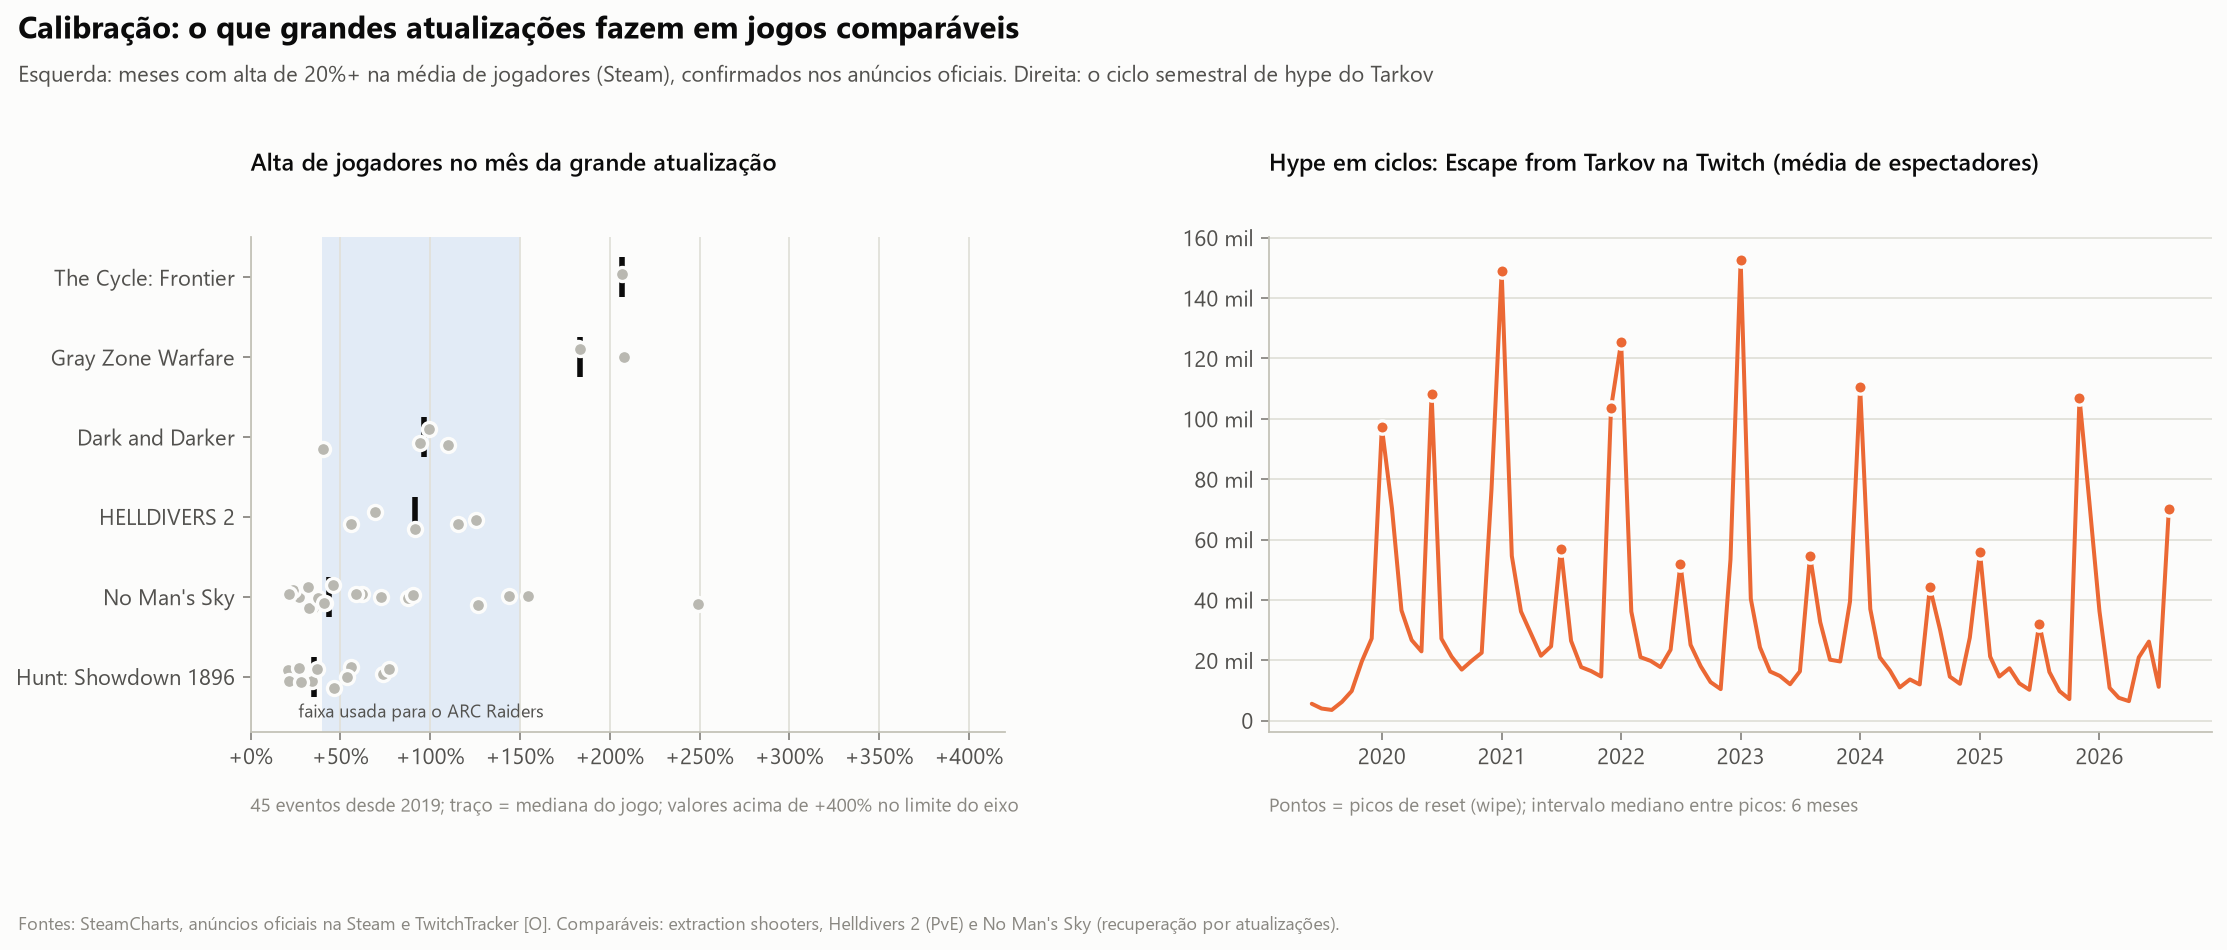

In [2]:
Image("../reports/figures/11a_calibracao_atualizacoes.png")

## 2. Jogadores até dez/2027

| Cenário (base) | Média de 2027 | Dez/2027 | Chance de terminar 2027 acima de set/2026 |
|---|---|---|---|
| Sem ação | 9,4 mil | 7,6 mil | 0% |
| Atualizações semestrais | 28,3 mil | 28,5 mil | 85% |
| + modo PvE | **32,5 mil** | **33,2 mil** | **94%** |
| + modo PvE (pessimista) | 12,5 mil | 6,0 mil | 0% |

(Média mensal de jogadores simultâneos na Steam; em todas as plataformas, ~2x.)

**Sem ação, o jogo definha** para ~8 mil jogadores na Steam. **Com a nova cadência, a curva vira um serrote**: cada atualização devolve a base a ~40 mil, e a queda entre elas é menor que a de 2026. O Frozen Trail sozinho deve **dobrar** a média de outubro (mediana de 42 mil, contra 21 mil em set/2026), somando a alta típica de uma grande atualização à volta de parte dos veteranos que abandonaram (grupo de 30% da Etapa 6).

**Engajamento, comportamento e expectativa:** o risco da cadência semestral é o intervalo. Na versão pessimista, a queda entre atualizações apaga o ganho de cada uma, e a base termina 2027 abaixo de hoje. O que separa os dois mundos é a **qualidade da atualização** (tamanho da alta e quanto dela fica), o que coloca o peso da decisão no Frozen Trail e no que ele mostrar entre outubro e dezembro.

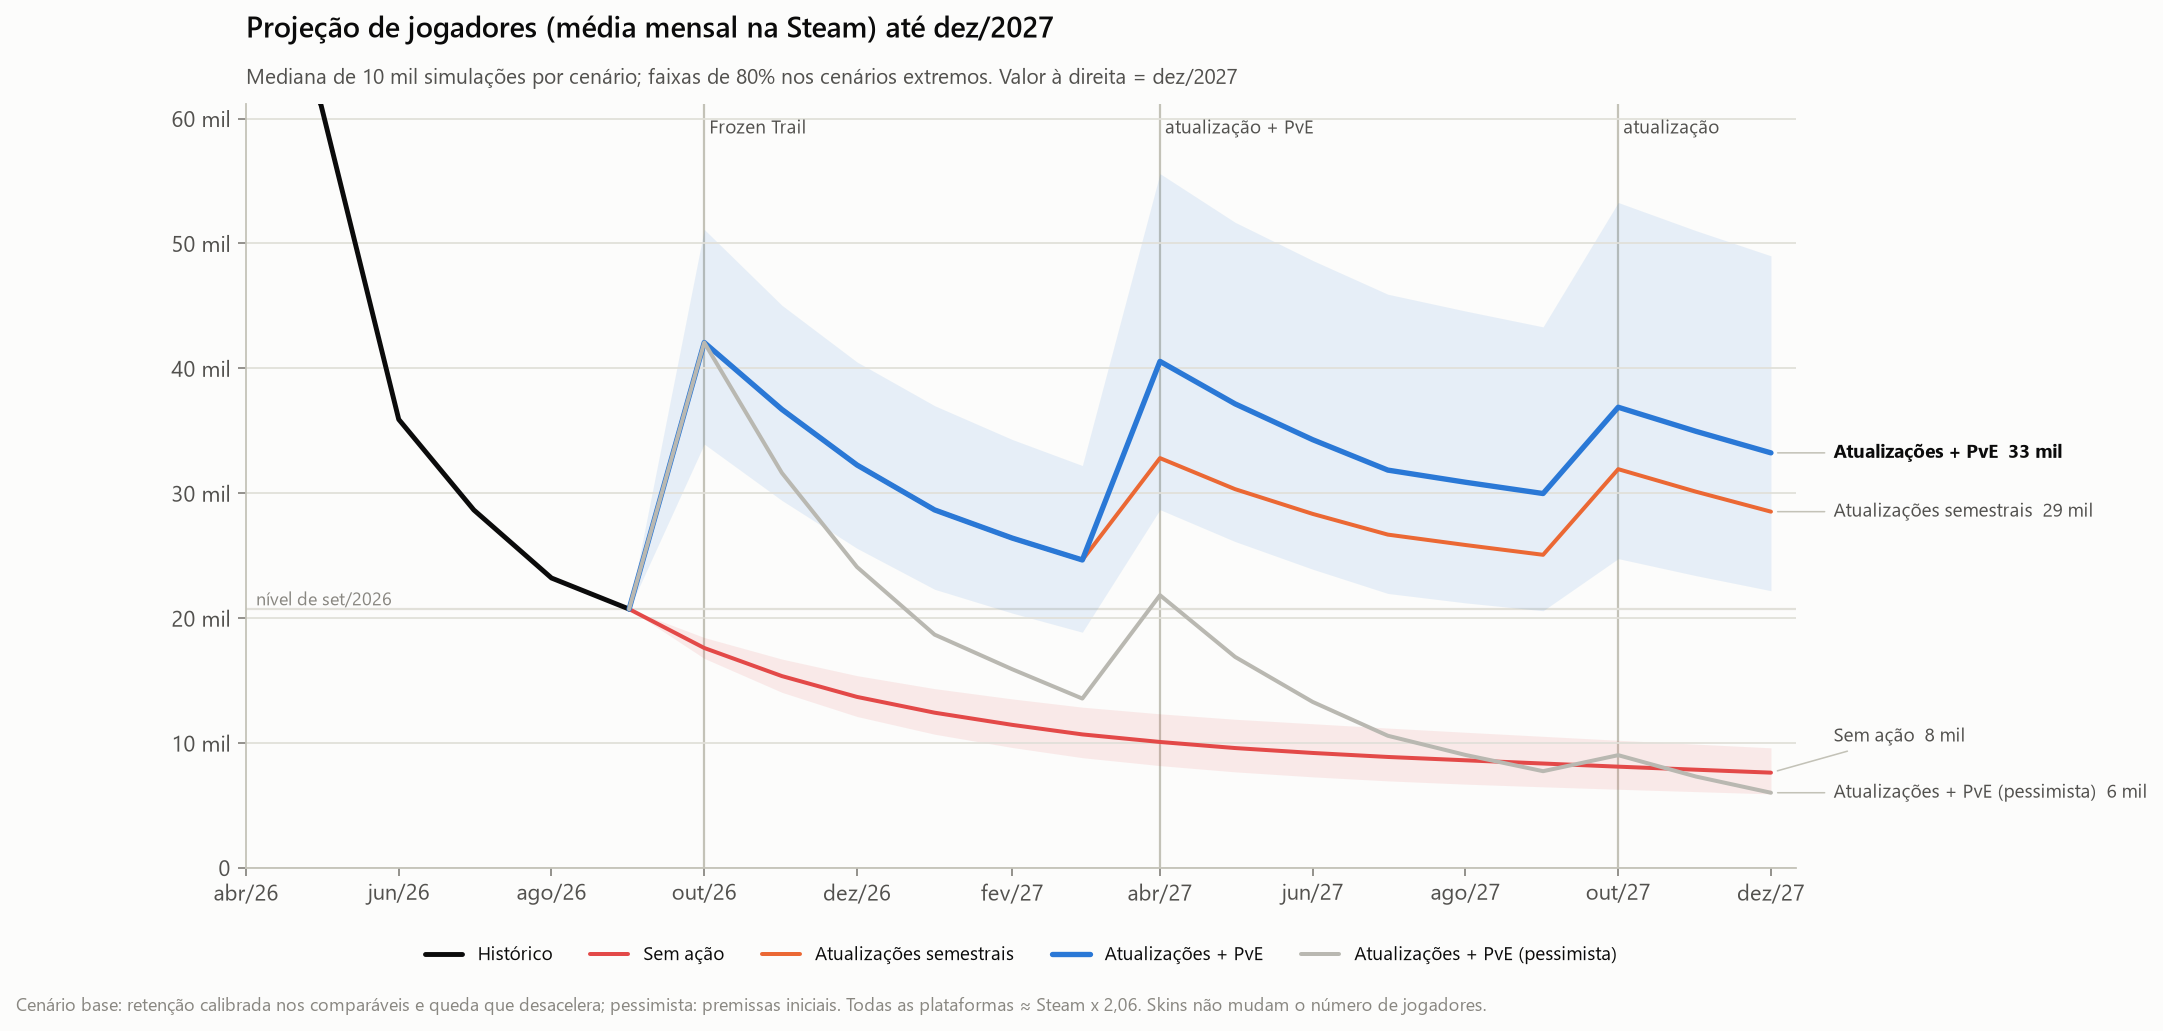

In [3]:
Image("../reports/figures/11b_projecao_jogadores.png")

## 3. Modo PvE: sustentabilidade

No cenário base, o PvE entra em abr/2027 e responde por **~45% da base** até o fim de 2027, próximo dos 37% de jogadores cooperativos que a Embark mediu. O ganho vem sobretudo da **volta de jogadores cooperativos** no lançamento do modo; o efeito de retenção sobre quem já joga é pequeno.

- **+15% de jogadores em 2027** em relação ao cenário só com atualizações (32,5 mil contra 28,3 mil na média do ano).
- **O saldo é positivo em todas as simulações**, mas isso decorre das premissas: a menor alta de lançamento (+10%) supera a maior perda possível de jogadores só-PvP (10% de 34% = 3,4% da base). Se o PvE não trouxer ninguém de volta, o efeito fica perto de zero.
- Fala com o grupo dos **casuais persistentes** (27% dos autores, Etapa 6), que mais pedem PvE e ainda jogam.

**Cuidado:** a alta no lançamento do PvE (+10% a +40%) é uma premissa do projeto [P], não calibrada. O teste de 13–20/10 vai dar o primeiro número real de adoção.

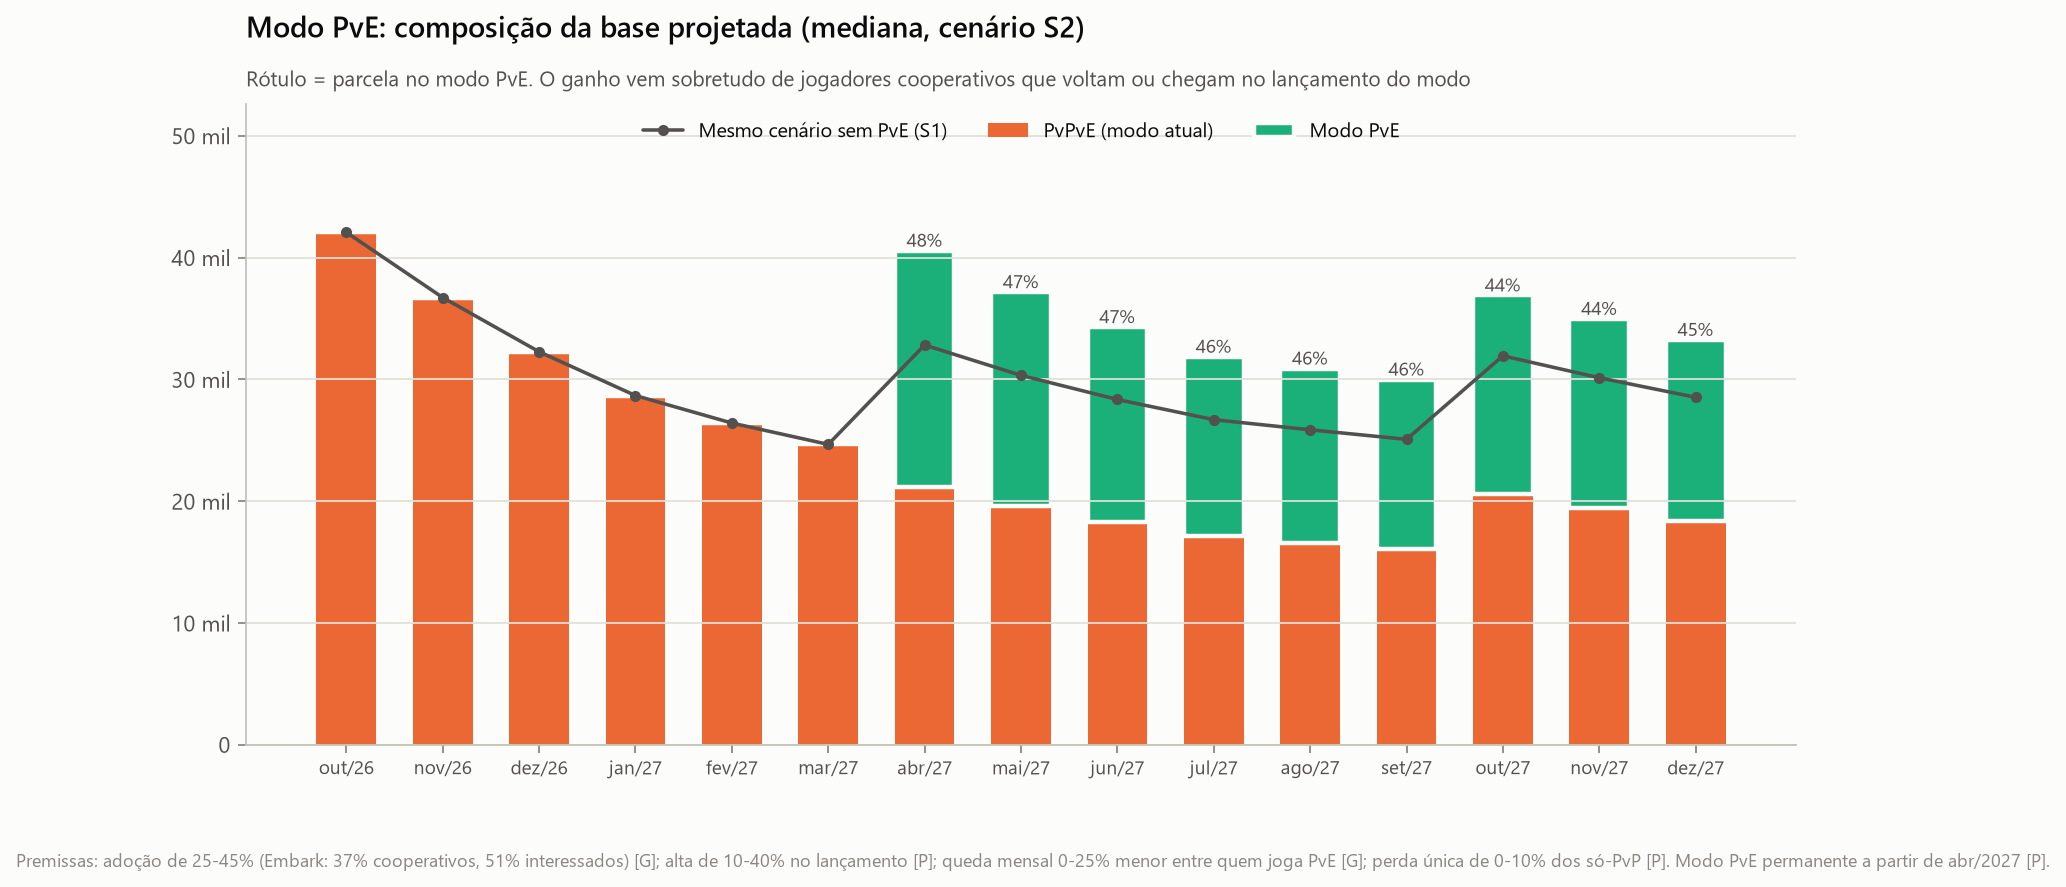

In [4]:
Image("../reports/figures/11c_projecao_pve.png")

## 4. Receita de 2027 por cenário

| Cenário | Base (mediana) | Faixa de 80% | Pessimista |
|---|---|---|---|
| Sem ação | US$ 34 mi | 26–43 | US$ 19 mi |
| Atualizações semestrais | US$ 102 mi | 71–145 | US$ 40 mi |
| + modo PvE | US$ 117 mi | 80–168 | US$ 45 mi |
| + skins de armas | **US$ 127 mi** | **87–183** | US$ 49 mi |

**Skins de armas:** US$ 9,6 mi em 2027 (4,7–18,7), ~8% da receita. A skin poder ser perdida para quem te mata reduz a conversão (premissa de −10% a −40%); nenhum grande jogo de tiro faz isso, então é a projeção mais incerta. As skins complementam, mas não mudam o destino do jogo: **o que move a receita é o número de jogadores**, e o que move os jogadores são as atualizações.

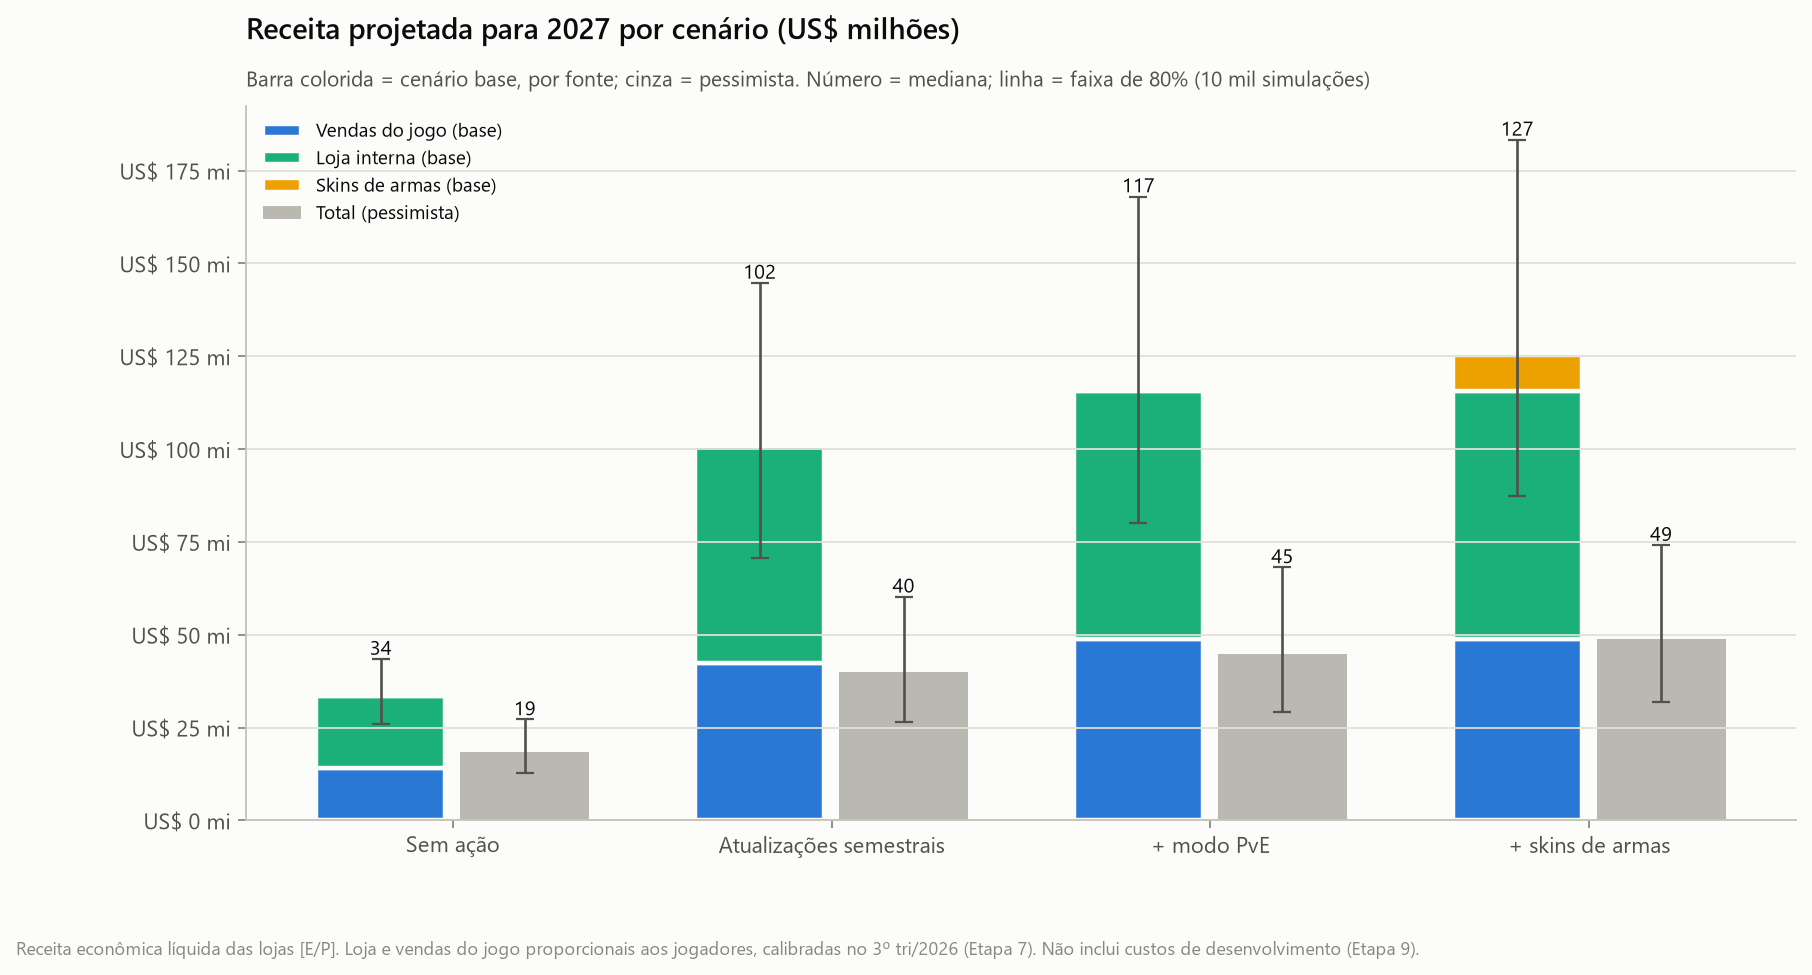

In [5]:
Image("../reports/figures/11d_receita_2027_cenarios.png")

## 5. O que mais pesa

As quatro premissas que mais mudam a receita de 2027 são todas sobre **jogadores**: o tamanho da alta de cada atualização (±US$ 35–39 mi), a velocidade da queda entre atualizações (±US$ 25 mi), a fração da alta que fica (±US$ 22–24 mi) e o gasto na loja por jogador (±US$ 20 mi). Skins e preço por unidade pesam pouco.

**Implicação:** o Frozen Trail funciona como teste da tese. Os números de out–dez/2026 (alta de jogadores, retenção após 3 meses, adoção no teste de PvE) resolvem as três maiores incertezas, e por isso a revisão de pós-lançamento já está no plano (Etapa 11).

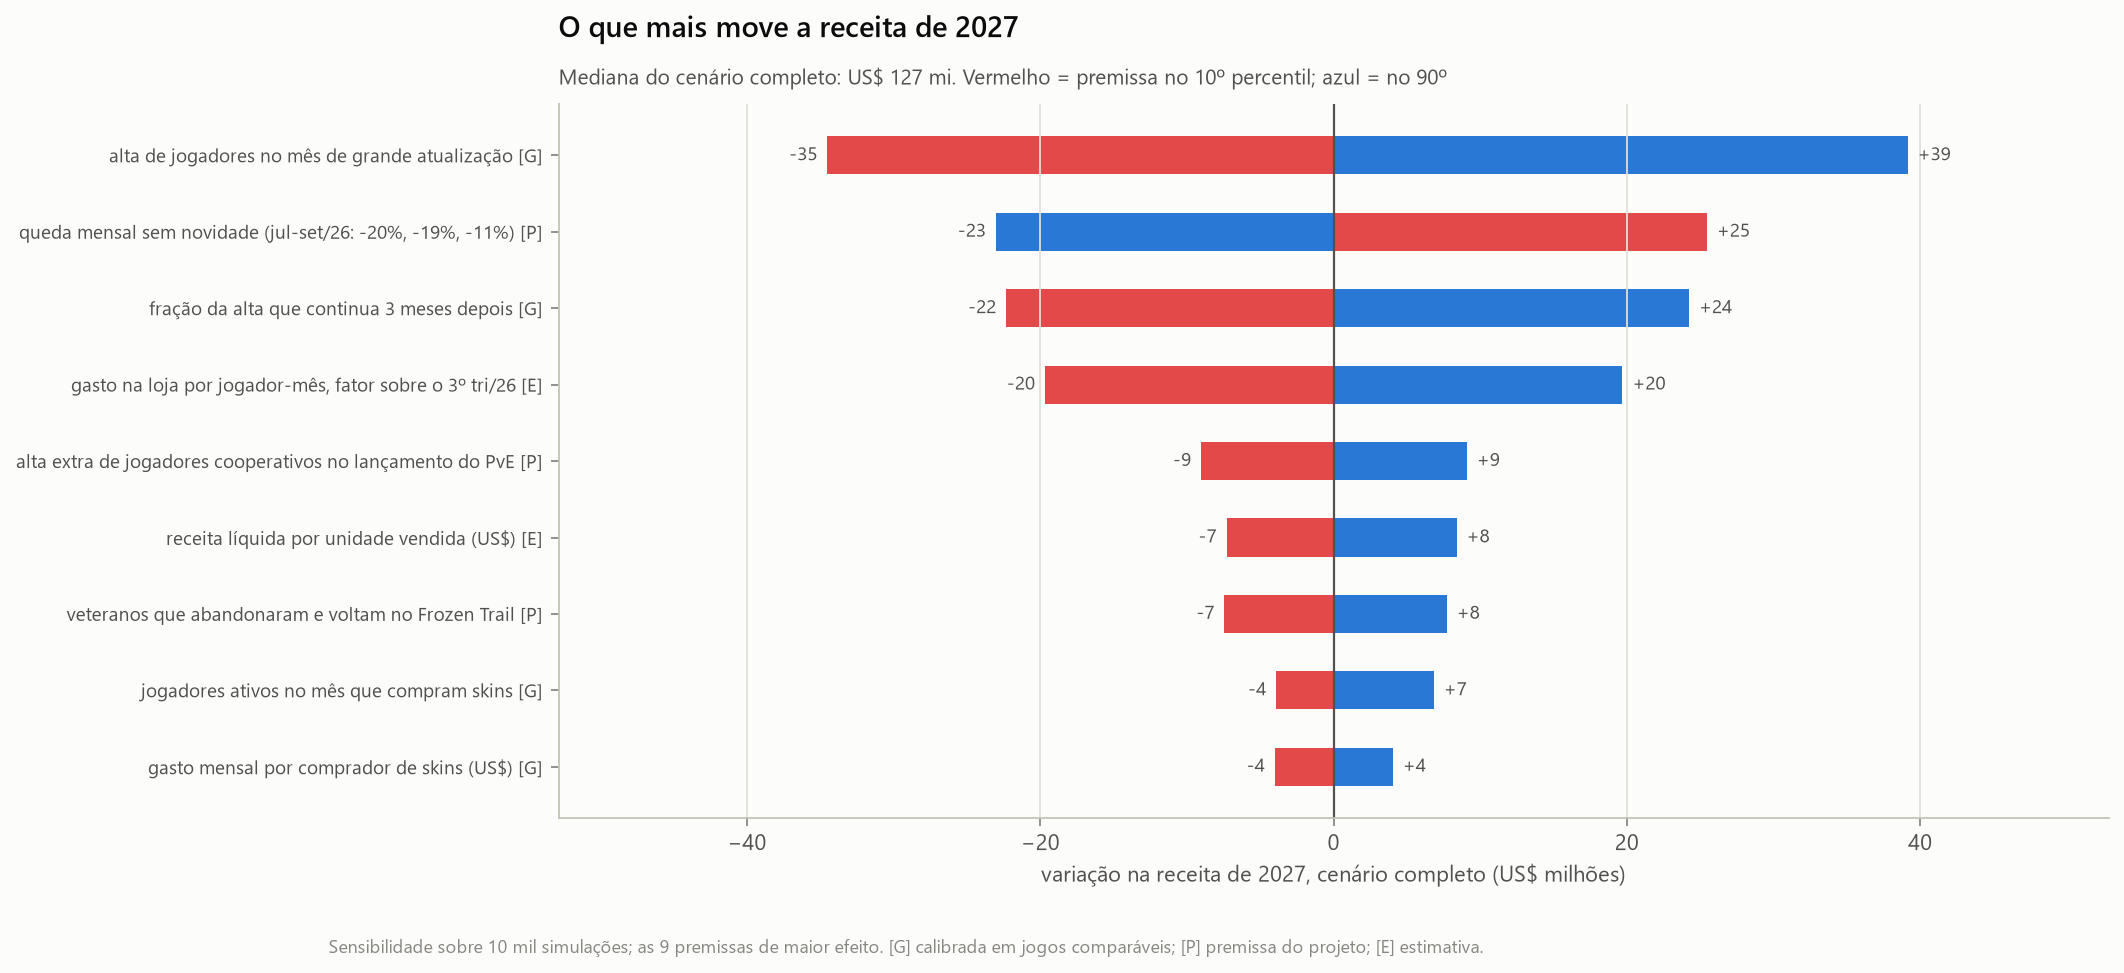

In [6]:
Image("../reports/figures/11e_sensibilidade_2027.png")

## Síntese

1. **A cadência semestral pode sustentar o jogo**, mas só se cada atualização repetir o padrão dos comparáveis. Cenário base: ~33 mil jogadores na Steam em dez/2027 (acima dos 21 mil de hoje) e ~US$ 100–127 mi de receita em 2027.
2. **No pessimista, a mesma estratégia não basta**: a base termina 2027 em ~6 mil e a receita fica em US$ 40–49 mi.
3. **PvE soma ~15%** e fala com quem ainda está no jogo; **skins somam ~8%** e são a aposta mais incerta.
4. **Sem ação, o jogo encolhe para ~8 mil jogadores e US$ 34 mi em 2027.**

A Etapa 9 cruza esses cenários com o custo de manter a equipe e com os indicadores do Frozen Trail para chegar à recomendação.